# Ecology Part

Dataset concernant des sites d'observation de chauves-souris

|         colonnes         |   type   | desc |
| :----------------------: | :------: | :--: |
|        survey_id         |   str    |      |
|        site_code         |   str    |      |
|       survey_start       | datetime |      |
|        survey_end        | datetime |      |
|      survey_method       |   str    |      |
|    observation_hours     |  float   |      |
|    observed_bat_count    |   int    |      |
| acoustic_detection_count |   int    |      |
|   nightly_visit_count    |   int    |      |
|     colony_estimate      |  float   |      |
| comparison_species_count |   int    |      |
|      survey_quality      |   str    |      |
|   weather_interference   |  float   |      |


In [46]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import STL
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

Je commence par importer tous les fichiers CSV nécessaires.

In [47]:
bats = pd.read_csv("./data/ecology/bat_surveys.csv")
report = pd.read_csv("./data/ecology/environmental_field_reports.csv")
env = pd.read_csv("./data/ecology/environmental_monthly.csv")
devices = pd.read_csv("./data/ecology/monitoring_device_operations.csv")
sites = pd.read_csv("./data/ecology/monitoring_sites.csv")
archad = pd.read_csv("./data/ecology/orchard_surveys.csv")



Pour l'instant, les données qui m'intéressent le plus sont les informations recueillies sur les chauves-souris.

In [48]:
bats.info()

<class 'pandas.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   survey_id                 4994 non-null   str    
 1   site_code                 4994 non-null   str    
 2   survey_start              4994 non-null   str    
 3   survey_end                4994 non-null   str    
 4   survey_method             4994 non-null   str    
 5   observation_hours         4994 non-null   str    
 6   observed_bat_count        4994 non-null   str    
 7   acoustic_detection_count  4994 non-null   str    
 8   nightly_visit_count       4994 non-null   str    
 9   colony_estimate           4994 non-null   float64
 10  comparison_species_count  4994 non-null   int64  
 11  observer_team             4974 non-null   str    
 12  survey_quality            4994 non-null   str    
 13  weather_interference      4994 non-null   str    
dtypes: float64(1), int6

Pour l'instant, les données qui m'intéressent le plus sont les informations recueillies sur les chauves-souris.

In [49]:
print(bats.head(20)["observed_bat_count"][19])

9 count


Et que ces valeurs ne sont pas au même format.

On va alors nettoyer les colonnes numériques et retirer tout caractère autre que ceux de 0 à 9, `.` ou `,`, puis changer leur type en `int` ou `float` en fonction.

In [50]:
float_col = [
    "colony_estimate",
    "weather_interference",
    "observation_hours"
]

int_col = [
    "acoustic_detection_count",
    "nightly_visit_count",
    "observed_bat_count",
    "comparison_species_count"
]

numeric_col = []
numeric_col.extend(float_col)
numeric_col.extend(int_col)

def remove_alphabetic_char(data: pd.DataFrame, col_names: list[str]) -> pd.DataFrame:
    data = data.copy()
    for name in col_names:
        data[name] = data[name].astype(str).str.replace(r"[^\d.,-]", "", regex=True)
    return data

bats = remove_alphabetic_char(bats, numeric_col)

print(bats["observed_bat_count"].head(20)[19])


9


In [51]:
def col_type_converter(data: pd.DataFrame, col_names: list[str], dtype) -> pd.DataFrame:
    data = data.copy()
    for name in col_names:
        col = data[name]
        if dtype in (float, int):
            col = col.astype(str).str.replace(",", ".", regex=False)
        data[name] = col.astype(dtype)
    return data



bats = col_type_converter(bats, float_col, float)
bats = col_type_converter(bats, int_col, int)

bats.info()


<class 'pandas.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   survey_id                 4994 non-null   str    
 1   site_code                 4994 non-null   str    
 2   survey_start              4994 non-null   str    
 3   survey_end                4994 non-null   str    
 4   survey_method             4994 non-null   str    
 5   observation_hours         4994 non-null   float64
 6   observed_bat_count        4994 non-null   int64  
 7   acoustic_detection_count  4994 non-null   int64  
 8   nightly_visit_count       4994 non-null   int64  
 9   colony_estimate           4994 non-null   float64
 10  comparison_species_count  4994 non-null   int64  
 11  observer_team             4974 non-null   str    
 12  survey_quality            4994 non-null   str    
 13  weather_interference      4994 non-null   float64
dtypes: float64(3), int6

Puis, je converti les string de date en datetime

In [52]:
date_col = [
    "survey_start",
    "survey_end"
]

def col_to_date(data: pd.DataFrame, col_names: list[str]):
    for name in col_names:
        data[name] = pd.to_datetime(data[name], format="mixed")
    return data

bats = col_to_date(bats, date_col)

bats.info()
bats["survey_start"].head()


<class 'pandas.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   survey_id                 4994 non-null   str           
 1   site_code                 4994 non-null   str           
 2   survey_start              4994 non-null   datetime64[us]
 3   survey_end                4994 non-null   datetime64[us]
 4   survey_method             4994 non-null   str           
 5   observation_hours         4994 non-null   float64       
 6   observed_bat_count        4994 non-null   int64         
 7   acoustic_detection_count  4994 non-null   int64         
 8   nightly_visit_count       4994 non-null   int64         
 9   colony_estimate           4994 non-null   float64       
 10  comparison_species_count  4994 non-null   int64         
 11  observer_team             4974 non-null   str           
 12  survey_quality            4994 

0   2019-01-05 18:00:00
1   2019-02-05 18:00:00
2   2019-03-05 18:00:00
3   2019-04-05 18:00:00
4   2019-05-05 18:00:00
Name: survey_start, dtype: datetime64[us]

Et enfin je supprimer les doublons

In [53]:
print(bats.duplicated().sum())
bats = bats.drop_duplicates()
print(bats.duplicated().sum())

2
0


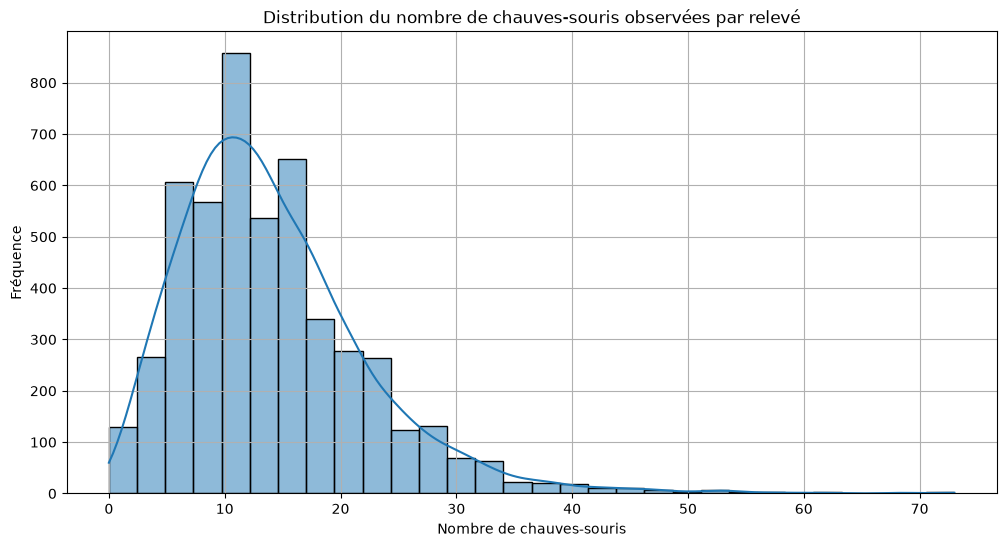

In [54]:
plt.figure(figsize=(12, 6))
sns.histplot(bats['observed_bat_count'], bins=30, kde=True)
plt.title('Distribution du nombre de chauves-souris observées par relevé')
plt.xlabel('Nombre de chauves-souris')
plt.ylabel('Fréquence')
plt.grid(True)
plt.show()

Avec ce graphe on remarque que le nombre de chauve souris suis une loi normal et que ce nombre ce concentre surtout enytr 5 et 15

Je fais une decomposition saisoniere avec la trend qui correspond a la tendence general, seasonal qui correspond a la saisonnalite (si il y a moins de chauve souris en hiver par exemple) et residual qui correspond au bruit, avec une periode de 12 car mes donnees sont mensuelles et robust a true pour reduire l'impact des valeurs extreme

In [55]:
bats_date = bats.copy()
bats_date = bats_date.sort_values("survey_start").set_index("survey_start")
stl = STL(bats_date["observed_bat_count"], period=12, robust=True)
res = stl.fit()

bats_date["trend"] = res.trend
bats_date["seasonal"] = res.seasonal
bats_date["residual"] = res.resid

window_size = 5
rolling_mean = bats_date["residual"].rolling(window=window_size, center=True).mean()
rolling_std = bats_date["residual"].rolling(window=window_size, center=True).std()

bats_date["z_score_residual"] = (bats_date["residual"] - rolling_mean) / rolling_std

anomalie_temp = bats_date[bats_date["z_score_residual"] < -1.5]
print("Baisses temporelles anormales détectées :")
print(anomalie_temp[["observed_bat_count", "residual", "z_score_residual"]])
print(anomalie_temp["site_code"].unique())

Baisses temporelles anormales détectées :
                     observed_bat_count   residual  z_score_residual
survey_start                                                        
2019-01-05 18:00:00                   4  -9.229844         -1.623067
2019-01-05 18:00:00                  14  -1.749284         -1.603005
2019-02-05 18:00:00                   3 -15.350392         -1.656261
2019-03-05 18:00:00                   7 -25.666227         -1.727007
2019-03-05 18:00:00                  14 -13.377198         -1.639263
...                                 ...        ...               ...
2025-04-05 18:00:00                   2 -19.302658         -1.526960
2025-04-05 18:00:00                   6 -13.117825         -1.618162
2025-05-05 18:00:00                   2 -22.319511         -1.587435
2025-05-05 18:00:00                   4 -15.759038         -1.551266
2025-06-05 18:00:00                   9 -11.877330         -1.650890

[155 rows x 3 columns]
<StringArray>
['KNT-YRX', 'TMB-QCB', 

In [57]:
numeric_col = [
    "mean_temperature_c",
    "rainfall_mm",
    "mean_humidity_pct",
    "vegetation_cover_pct",
    "habitat_disturbance_index",
    "pesticide_index",
    "data_completeness_pct"
]

env = remove_alphabetic_char(env, numeric_col)


env = col_type_converter(env, numeric_col, float)
env.info()

<class 'pandas.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   site_code                  4994 non-null   str    
 1   reporting_month            4994 non-null   str    
 2   mean_temperature_c         4994 non-null   float64
 3   rainfall_mm                4994 non-null   float64
 4   mean_humidity_pct          4994 non-null   float64
 5   vegetation_cover_pct       4984 non-null   float64
 6   habitat_disturbance_index  4994 non-null   float64
 7   pesticide_index            4979 non-null   float64
 8   land_use_category          4994 non-null   str    
 9   weather_exception_code     204 non-null    str    
 10  data_completeness_pct      4994 non-null   float64
dtypes: float64(7), str(4)
memory usage: 429.3 KB


Puis j'utilise une isolation forest pour reduire le nombre de sites

In [58]:
m = bats_date.merge(env, on=["site_code"], how="left")

print(m["site_code"].unique().size)
features = [ 
    'observed_bat_count', 
    'acoustic_detection_count', 
    'nightly_visit_count', 
    'mean_temperature_c', 
    'rainfall_mm', 
    'mean_humidity_pct', 
    'vegetation_cover_pct', 
    'pesticide_index', 
    'habitat_disturbance_index' 
]

scaler = StandardScaler()
x_scale = scaler.fit_transform(m[features].fillna(m[features].median()))

iso_forest = IsolationForest(contamination=0.05, random_state=42)
m["anomalie_forest"] = iso_forest.fit_predict(x_scale)


anomalies_multivariees = m[m["anomalie_forest"] == -1]
print(anomalies_multivariees["site_code"].unique())

64
<StringArray>
['AVL-SEY', 'AVL-NMQ', 'AVL-FNQ', 'AVL-MAR', 'TMB-BRC', 'TMB-NAC', 'KNT-GGN',
 'KNT-UJJ', 'KNT-YRX', 'KNT-BME', 'KNT-CYP', 'AVL-GRB', 'AVL-DER', 'AVL-RNY',
 'AVL-RBC', 'KNT-TLQ', 'AVL-YAU', 'KNT-JAK', 'AVL-BWK', 'KNT-XAC', 'KNT-CHP',
 'KNT-LUM', 'AVL-TRP', 'TMB-SXP', 'KNT-JQG', 'KNT-DMJ', 'AVL-KAR', 'KNT-GKR',
 'KNT-VLB', 'KNT-WUQ', 'AVL-VEL', 'AVL-ECJ', 'TMB-HVD', 'AVL-ORR', 'KNT-SEN',
 'TMB-DLQ', 'TMB-HQL', 'TMB-CKU', 'KNT-QWU', 'KNT-YRG', 'AVL-NFR', 'KNT-KES',
 'AVL-HUA', 'AVL-ARU', 'TMB-GZX', 'TMB-AYQ', 'AVL-ABG', 'KNT-TEX', 'TMB-WST']
Length: 49, dtype: str


Et aussi j'applique une LOF pour encore reduire ce nombre

In [59]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
m["anomalie_lof"] = lof.fit_predict(x_scale)

anomalies_multivariees = m[(m["anomalie_lof"] == -1)]
print(anomalies_multivariees["site_code"].unique())

<StringArray>
['AVL-BVM', 'AVL-ABG', 'AVL-VEL', 'AVL-YAU', 'KNT-SEN', 'TMB-NAC', 'KNT-YRG',
 'KNT-VXR', 'AVL-DER', 'TMB-DLQ', 'TMB-VZT', 'TMB-HQL', 'AVL-BWK', 'AVL-RNY',
 'TMB-GWP', 'AVL-MAR', 'KNT-XAC', 'KNT-TEX', 'TMB-WQL', 'AVL-HTY', 'TMB-SXP',
 'TMB-XTD', 'KNT-UJJ', 'KNT-LUM', 'AVL-TRP', 'TMB-SKZ', 'KNT-DMJ', 'AVL-FNQ',
 'KNT-QWU', 'AVL-ECJ', 'TMB-WST', 'KNT-WUQ', 'AVL-HUA', 'AVL-NFR', 'AVL-SEY',
 'AVL-KAR', 'TMB-HVD', 'KNT-NNM', 'KNT-VLB', 'TMB-BRC', 'KNT-JAK', 'AVL-ORR',
 'KNT-CHP', 'KNT-GKR', 'AVL-NMQ', 'AVL-ARU', 'TMB-PEL', 'KNT-YRX', 'KNT-CYP',
 'AVL-GRB', 'TMB-HFR', 'TMB-CKU', 'TMB-GZX', 'TMB-WYT', 'AVL-RBC', 'AVL-FNM',
 'TMB-UVF', 'KNT-KES', 'TMB-AYQ', 'KNT-GGN', 'KNT-BME', 'KNT-TLQ', 'KNT-JQG',
 'TMB-QCB']
Length: 64, dtype: str


Cette approche ne réduit pas très bien le nombre de sites. Comme j’ai du mal à les utiliser, j’ai décidé de reprendre à zéro et de tester une approche différente plus basique.

Je me concentre sur le **z-score** pour repérer des baisses anormales, puis j’intègre ensuite les problèmes de matériel et les problèmes temporels. Enfin, j’explore les logs liés aux dates des baisses de population qui ne sont liées ni à une défaillance de matériel d’observation, ni à une météo anormale.

In [60]:
def z_score(s):
    m = s.median()
    e = (s - m).abs().median()
    return 0.6745 * (s - m) / e if e else pd.Series(np.nan, index=s.index)

D’abord, je regarde les baisses mensuelles de chauves-souris avec le **z-score** comme critère de comparaison.

Pour cela, je calcule le pourcentage de modification entre la moyenne d’un mois et celle du même mois de l’année précédente. Puis, j’utilise ce pourcentage pour calculer un **z-score**. Si ce **z-score** montre une diminution anormale, alors il y a une anomalie sur le site liée.

In [61]:
bats_month = bats.copy()
bats_month['month'] = bats["survey_start"].dt.to_period('M')

monthly_avg = bats_month.groupby(["site_code", "month"]).agg({
    'observed_bat_count': ['mean', 'std', 'count']
}).reset_index()
monthly_avg.columns = ['site_code', 'month', 'mean_bats', 'std_bats', 'n_obs']

monthly_avg['month_of_year'] = monthly_avg['month'].dt.month
monthly_avg['year'] = monthly_avg['month'].dt.year

monthly_avg = monthly_avg.sort_values(['site_code', 'month']).reset_index(drop=True)

monthly_avg['prev_mean'] = monthly_avg.groupby(['site_code', 'month_of_year'])['mean_bats'].shift(1)
monthly_avg['pct_change'] = (monthly_avg['mean_bats'] - monthly_avg['prev_mean']) / monthly_avg['prev_mean'] * 100


monthly_avg.info()

monthly_avg['z_score'] = z_score(monthly_avg['pct_change'])

anomaly = monthly_avg[monthly_avg['z_score'] < -1.5]
print(anomaly[['site_code', 'month']])

<class 'pandas.DataFrame'>
RangeIndex: 4992 entries, 0 to 4991
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype    
---  ------         --------------  -----    
 0   site_code      4992 non-null   str      
 1   month          4992 non-null   period[M]
 2   mean_bats      4992 non-null   float64  
 3   std_bats       0 non-null      float64  
 4   n_obs          4992 non-null   int64    
 5   month_of_year  4992 non-null   int64    
 6   year           4992 non-null   int64    
 7   prev_mean      4224 non-null   float64  
 8   pct_change     4224 non-null   float64  
dtypes: float64(4), int64(3), period[M](1), str(1)
memory usage: 351.1 KB
     site_code    month
561    AVL-FNQ  2020-04
579    AVL-FNQ  2021-10
600    AVL-FNQ  2023-07
605    AVL-FNQ  2023-12
615    AVL-FNQ  2024-10
...        ...      ...
4286   TMB-PEL  2025-03
4310   TMB-QCB  2020-09
4443   TMB-SKZ  2025-04
4566   TMB-UVF  2022-07
4819   TMB-WST  2024-02

[72 rows x 2 columns]


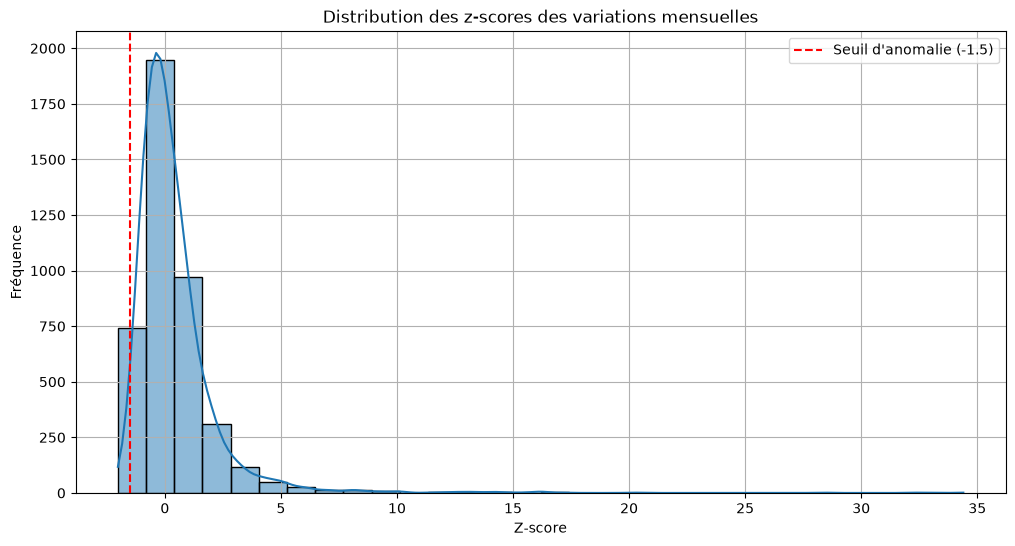

In [62]:
plt.figure(figsize=(12, 6))
sns.histplot(monthly_avg['z_score'].dropna(), bins=30, kde=True)
plt.axvline(x=-1.5, color='red', linestyle='--', label='Seuil d\'anomalie (-1.5)')
plt.title('Distribution des z-scores des variations mensuelles')
plt.xlabel('Z-score')
plt.ylabel('Fréquence')
plt.legend()
plt.grid(True)
plt.show()

Sur ce graphe on peut voir plusieurs choses :

Concentration autour de 0:
- La plupart des variations mensuelles sont naturelles (ex. : fluctuations saisonnières résiduelles, bruit aléatoire).
- Pas de biais systématique : La médiane des variations est proche de 0, ce qui valide la robustesse de la méthode.

Asymétrie positive :
- Plus de hausses que de baisses, ce qui suggère que la population de chauves-souris a globalement tendance à augmenter d'un mois à l'autre (hors anomalies).
- Les baisses sont plus rares et plus marquées (queue à gauche).
- 
Seuil à -1.5 :
- 72 anomalies détectées (z-score < -1.5) sur l'ensemble des données.
- Ces anomalies représentent les baisses les plus significatives, non expliquées par la tendance ou la saisonnalité.
- Un z-score de -2.0 signifie que la baisse est 2 écarts-types en dessous de la médiane, ce qui est très improbable sous des conditions normales.

Ensuite, je vais fusionner ma DataFrame sur les chauves-souris avec le DataFrame des informations liées au matériel.

In [63]:
# devices.info()
devices = col_type_converter(devices, ['uptime_pct', 'acoustic_quality'], float)
devices = col_to_date(devices, ['operation_start', 'operation_end'])
devices_month = devices.copy()
devices_month['month'] = devices['operation_start'].dt.to_period('M')

device_issues = pd.merge(
    anomaly,
    devices_month,
    on=['site_code', 'month'],
    how='left'
)

env.info()
env = col_to_date(env, ['reporting_month'])
env_monthly = env
env_monthly['month'] = env['reporting_month'].dt.to_period('M')

devices_env_issues = pd.merge(
    device_issues,
    env_monthly,
    on=['site_code', 'month'],
    how='left'
)

devices.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4994 entries, 0 to 4993
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   site_code                  4994 non-null   str    
 1   reporting_month            4994 non-null   str    
 2   mean_temperature_c         4994 non-null   float64
 3   rainfall_mm                4994 non-null   float64
 4   mean_humidity_pct          4994 non-null   float64
 5   vegetation_cover_pct       4984 non-null   float64
 6   habitat_disturbance_index  4994 non-null   float64
 7   pesticide_index            4979 non-null   float64
 8   land_use_category          4994 non-null   str    
 9   weather_exception_code     204 non-null    str    
 10  data_completeness_pct      4994 non-null   float64
dtypes: float64(7), str(4)
memory usage: 429.3 KB


,operation_start,operation_end,uptime_pct,acoustic_quality
count,4994,4994,4994.000000,4994.000000
mean,2022-03-17 12:36:02.595114,2022-04-16 22:45:35.403684,92.526131,78.991270
min,2019-01-01 00:00:00,2019-01-31 23:59:59,23.100000,20.000000
25%,2020-08-01 00:00:00,2020-08-31 23:59:59,90.200000,73.900000
50%,2022-04-01 00:00:00,2022-04-30 23:59:59,93.800000,79.300000
75%,2023-11-01 00:00:00,2023-11-30 23:59:59,97.300000,84.600000
max,2025-06-01 00:00:00,2025-06-30 23:59:59,100.000000,100.000000
std,NaN,NaN,7.924973,8.505031


Je vais supprimer tous les sites qui ont soit eu un problème de matériel, soit eu des problèmes météorologiques.

Là encore, j’utilise un **z-score** sur les colonnes `habitat_disturbance_index`, `pesticide_index` et `rainfall_mm`. Pour la colonne `uptime_pct`, je choisis de plutôt faire une élimination si le temps est en dessous de 90 %, car la plupart des observations sont à 90 %. J’enlève donc les problèmes les plus marqués.

In [64]:
for col in ['habitat_disturbance_index', 'pesticide_index', 'rainfall_mm', 'uptime_pct']:
    med = devices_env_issues[col].median()
    eam = (devices_env_issues[col] - med).abs().median()
    devices_env_issues[f'z_{col}'] = 0.6745 * (devices_env_issues[col] - med) / eam


site_anomalie = []
for _, row in devices_env_issues.iterrows():
    site = row['site_code']
    month = row['month']
    z_score = row['z_score']
    problems = []

    has_material_issue = (
        (row['uptime_pct'] < 90)
    )

    has_env_issue = (
        (row['z_habitat_disturbance_index'] > 1.5) or
        (row['z_pesticide_index'] > 1.5) or
        (row['z_rainfall_mm'] > 1.5)
    )

    if not has_material_issue and not has_env_issue:
        pair = {'site': site, 'period': month}
        if pair not in site_anomalie:
            site_anomalie.append(pair)

print(site_anomalie)
print(len(site_anomalie))

devices_env_issues.describe()


[{'site': 'AVL-FNQ', 'period': Period('2021-10', 'M')}, {'site': 'AVL-FNQ', 'period': Period('2023-07', 'M')}, {'site': 'AVL-FNQ', 'period': Period('2024-10', 'M')}, {'site': 'AVL-GRB', 'period': Period('2020-01', 'M')}, {'site': 'AVL-GRB', 'period': Period('2021-08', 'M')}, {'site': 'AVL-GRB', 'period': Period('2024-11', 'M')}, {'site': 'AVL-GRB', 'period': Period('2025-02', 'M')}, {'site': 'AVL-MAR', 'period': Period('2021-06', 'M')}, {'site': 'AVL-NFR', 'period': Period('2022-11', 'M')}, {'site': 'AVL-NFR', 'period': Period('2022-12', 'M')}, {'site': 'AVL-ORR', 'period': Period('2024-08', 'M')}, {'site': 'AVL-RNY', 'period': Period('2022-09', 'M')}, {'site': 'AVL-VEL', 'period': Period('2020-04', 'M')}, {'site': 'AVL-VEL', 'period': Period('2024-02', 'M')}, {'site': 'KNT-DMJ', 'period': Period('2023-02', 'M')}, {'site': 'KNT-JQG', 'period': Period('2021-02', 'M')}, {'site': 'KNT-KES', 'period': Period('2024-05', 'M')}, {'site': 'KNT-LUM', 'period': Period('2023-09', 'M')}, {'site': 

,mean_bats,std_bats,n_obs,month_of_year,year,prev_mean,pct_change,z_score,operation_start,operation_end,...,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct,z_habitat_disturbance_index,z_pesticide_index,z_rainfall_mm,z_uptime_pct
count,72.000000,0.0,72.0,72.000000,72.000000,72.000000,72.000000,72.000000,72,72,...,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,7.200000e+01
mean,1.944444,NaN,1.0,6.430556,2022.527778,12.194444,-84.825137,-1.716437,2022-12-24 08:40:00,2023-01-23 17:19:59,...,184.662500,78.070833,53.077778,43.913889,31.087500,95.791667,0.101405,-0.249057,-0.057857,-4.462601e-01
min,0.000000,NaN,1.0,1.000000,2020.000000,2.000000,-100.000000,-2.023500,2020-01-01 00:00:00,2020-01-31 23:59:59,...,53.400000,62.300000,15.600000,0.000000,0.000000,88.200000,-2.496833,-2.003745,-1.788777,-1.030145e+01
25%,1.000000,NaN,1.0,3.750000,2021.000000,6.000000,-88.544892,-1.791706,2021-09-23 12:00:00,2021-10-24 05:59:59,...,134.825000,73.375000,40.775000,33.250000,16.100000,94.275000,-0.529542,-1.095004,-0.715049,-6.080720e-01
50%,2.000000,NaN,1.0,7.000000,2023.000000,11.000000,-83.333333,-1.686250,2023-04-16 00:00:00,2023-05-16 11:59:59,...,189.050000,78.600000,54.150000,42.200000,35.500000,95.700000,0.000000,0.000000,0.000000,1.453698e-15
75%,3.000000,NaN,1.0,10.000000,2024.000000,17.000000,-77.777778,-1.573833,2024-05-01 00:00:00,2024-05-31 23:59:59,...,235.850000,82.975000,64.825000,55.600000,43.725000,97.325000,0.792833,0.464248,0.617138,6.642803e-01
max,6.000000,NaN,1.0,12.000000,2025.000000,36.000000,-75.000000,-1.517625,2025-05-01 00:00:00,2025-05-31 23:59:59,...,332.400000,89.500000,98.000000,84.400000,62.700000,100.000000,2.496833,1.535264,1.890314,1.614712e+00
std,1.471694,NaN,0.0,3.491746,1.678130,7.330505,7.946993,0.160807,NaN,NaN,...,69.333861,6.282850,17.201197,20.210605,18.020403,2.433380,1.195794,1.017135,0.914285,2.141763e+00


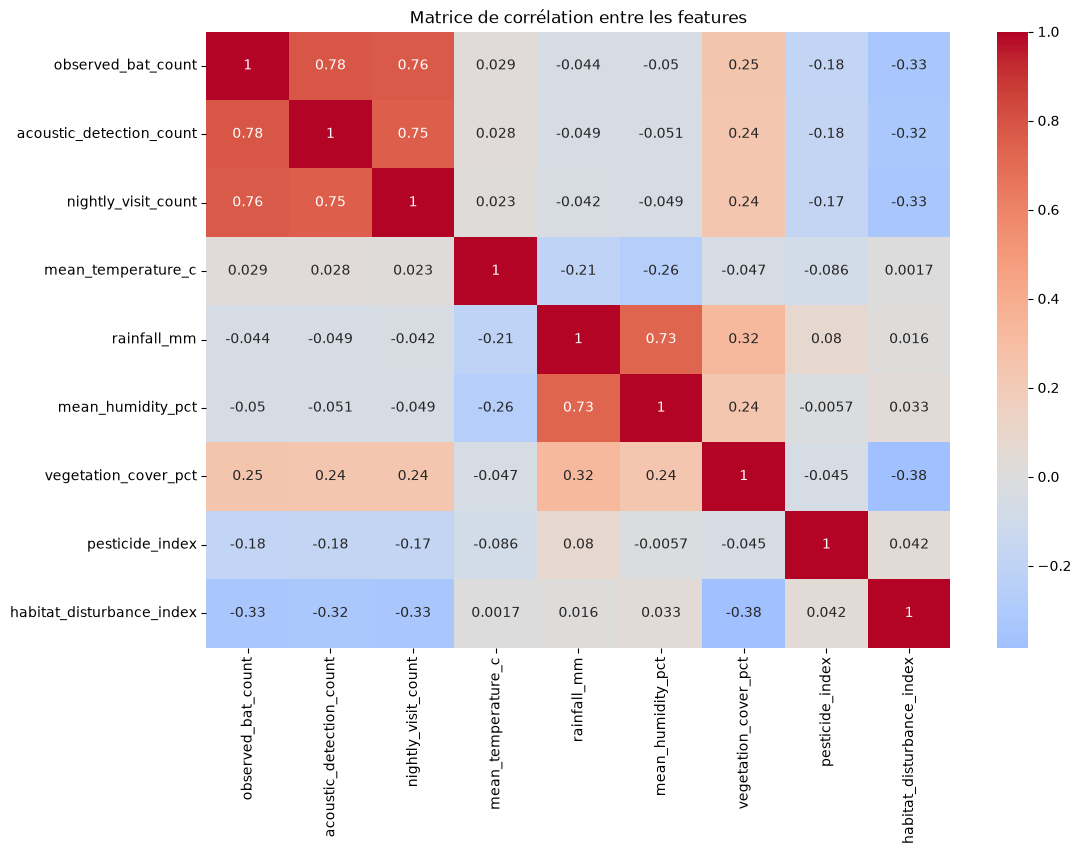

In [65]:
plt.figure(figsize=(12, 8))
corr = m[features].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Matrice de corrélation entre les features')
plt.show()

On voit que le nombre de chauve souris est correler au valeur de m'environnement et surtout par la valeur de habiat_disturbance_index

On garde les site qui n'on eu aucun probleme technique et pas de grand probleme liée a l'environnement. On recupere ensuite tout les logs liee a ces sites

In [66]:
print(report['site_code'].unique())

report = col_to_date(report, ['reporting_period'])

report_site = report.copy()

anom = pd.DataFrame(site_anomalie).drop_duplicates()

merged = report.merge(anom, left_on='site_code', right_on='site', how='inner')

merged['ecart_mois'] = (
    (merged['reporting_period'].dt.year - merged['period'].dt.year) * 12
    + (merged['reporting_period'].dt.month - merged['period'].dt.month)
).abs()

report_site = (merged[merged['ecart_mois'] <= 1]
               .drop_duplicates(subset=['site_code', 'reporting_period'])
               .reset_index(drop=True))

print(report_site.shape)
print(report_site[['site_code', 'reporting_period', 'period', 'ecart_mois']]
      .sort_values(['site_code', 'reporting_period']))


<StringArray>
['KNT-KES', 'KNT-JAK', 'KNT-JQG', 'KNT-VLB', 'KNT-CHP', 'KNT-YRG', 'KNT-WUQ',
 'KNT-DMJ', 'KNT-GGN', 'KNT-QWU', 'KNT-TLQ', 'KNT-UJJ', 'KNT-VXR', 'KNT-TEX',
 'KNT-BME', 'KNT-XAC']
Length: 16, dtype: str
(4, 15)
  site_code reporting_period   period  ecart_mois
0   KNT-KES       2024-04-01  2024-05           1
1   KNT-VLB       2020-07-01  2020-07           0
3   KNT-XAC       2023-12-01  2023-11           1
2   KNT-YRG       2024-03-01  2024-04           1


Comme il ne reste que 4 logs et c'est assez simple d'aller verifier manuellement mais je vais quand meme utiliser l'algo de TF-IDF pour regarder si un ou plusieurs ne sont pas similaire au autres

In [67]:
import re
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

def clean_text(txt):
    txt = txt.lower()                          # minuscules
    txt = re.sub(r"[^\w\s]", " ", txt)         # ponctuation
    txt = re.sub(r"\s+", " ", txt).strip()
    return txt

report_site['clean'] = report['text'].apply(clean_text)


tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1) 
M = tfidf.fit_transform(report_site['clean'])
for i, row in report_site.iterrows():
    scores = pd.Series(M[i].toarray()[0], index=tfidf.get_feature_names_out())
    top = scores.nlargest(8)
    print(f"{row['site_code']} {row['reporting_period']} : {', '.join(top.index)}")

S = cosine_similarity(M)

np.fill_diagonal(S, 0)

report_site['sim_moyenne'] = S.mean(axis=0)
report_site['plus_proche'] = S.max(axis=0)

print(report_site[['site_code', 'reporting_period', 'sim_moyenne', 'plus_proche']].sort_values('sim_moyenne'))

KNT-KES 2024-04-01 00:00:00 : the, was, and, access, not, with, acoustic, and the
KNT-VLB 2020-07-01 00:00:00 : and, the, cycle, maintenance cycle, sensor, sensor maintenance, interval, maintenance
KNT-YRG 2024-03-01 00:00:00 : and, the, habitat, assessment, disturbance assessment, disturbance, habitat disturbance, interval
KNT-XAC 2023-12-01 00:00:00 : and, the, exception, exception review, rainfall, rainfall exception, review, interval
  site_code reporting_period  sim_moyenne  plus_proche
0   KNT-KES       2024-04-01     0.179422     0.258323
1   KNT-VLB       2020-07-01     0.442582     0.769771
3   KNT-XAC       2023-12-01     0.445734     0.813573
2   KNT-YRG       2024-03-01     0.453895     0.813573


On obtient donc un log sur **KNT-KES**, qui est très différent des autres. Quand on va voir ce qu’il contient, on découvre qu’après une inspection, on a constaté une baisse du nombre de chauves-souris, alors que les instruments de mesure et les conditions météorologiques n’ont rien d’anormal.
On voit aussi qu’il y a eu des traces non identifiées sur le site, ce qui laisse croire à une effraction par des braconniers.